# Phase 1: Perception

## Section 1 - Purpose and overview

Phase 1 of the thesis pipeline: recognizing the Mr Potato Head pieces in egocentric frames recorded with an XR headset, without training any model. C-RADIOv4 is used as a frozen feature extractor: each frame becomes a grid of 16x16 patches, each described by a 1152-dimensional vector. Each class (10 pieces plus background and hand) is represented by a prototype, the normalized mean of its annotated patches in a few reference frames. Each patch of a new frame takes the class of the most similar prototype (cosine similarity), with a margin rejecting uncertain pieces to background.

Structure: configuration (2); model and features (3); dataset and split (4); from annotations to patch labels (5); prototypes (6); support-set gallery (7); prototype similarity (8); classifier (9); qualitative evaluation on validation frames (10); video pipeline (11); latency (12); limitations; sensitivity checks (Appendix A).

Each section ends with Observations (what the results show) and References (the literature justifying the choices). Provisional values are marked as such in Section 2.

## Section 2 - Configuration

All paths, classes and hyperparameters in one place. Provisional values are marked as such.

In [1]:
# 2.1 Run once per environment, then leave it commented
# %pip install -q shapely pandas scikit-learn einops scipy opencv-python

In [2]:
# 2.2 Imports 
import json
import sys
import time
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image
from sklearn.decomposition import PCA
import transformers


In [3]:
# 2.3 Paths and shared module
# One single project root. In this way the notebook can be executed everywhere
# Separated outputs per notebook
# Folder existence check
PROJECT_ROOT = Path.cwd().parent
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))   # makes src/perception importable from notebooks/

MODEL_DIR = PROJECT_ROOT / "models" / "c_radio_weights"
FRAMES_DIR = PROJECT_ROOT / "data" / "extracted_frames"
VIDEOS_DIR = PROJECT_ROOT / "data" / "raw_videos"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "phase_1_perception"
PROTOTYPES_PATH = OUTPUT_DIR / "prototypes.npz"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for name, path in {"MODEL_DIR": MODEL_DIR, "FRAMES_DIR": FRAMES_DIR, "VIDEOS_DIR": VIDEOS_DIR, "SRC_DIR": SRC_DIR}.items():
    status = "OK" if path.exists() else "MISSING"
    print(f"[{status}] {name}: {path}")

# Shared code (src/perception), used by every Phase 1 notebook
from perception.features import FeatureExtractor
from perception.labels import sequence_of, check_annotation, rasterize_annotation, patch_label_grid
from perception.prototypes import (l2_normalize, build_prototypes, stack_prototypes,
                                   save_prototypes, load_prototypes, classify_patches)
from perception.visualization import label_grid_to_rgb, render_overlay


[OK] MODEL_DIR: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\models\c_radio_weights
[OK] FRAMES_DIR: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\data\extracted_frames
[OK] VIDEOS_DIR: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\data\raw_videos
[OK] SRC_DIR: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\src


In [4]:
# 2.4 Official class list, defined once in src/perception/classes.py and shared by all notebooks.
# Annotations are checked against it in Section 4, and its order fixes the color of each class in every plot.
from perception.classes import (CLASS_NAMES, BACKGROUND_LABEL, HAND_LABEL, PIECE_LABELS, LEGACY_LABELS,
                                BACKGROUND_ID, IGNORE_ID, PATCH_LABEL_NAMES, CLASS_COLORS)

print(f"{len(CLASS_NAMES)} classes: {CLASS_NAMES}")


12 classes: ['background', 'body', 'base', 'hat', 'eyes', 'ear', 'nose', 'moustache', 'mouth', 'arm_1', 'arm_2', 'hand']


In [5]:
# 2.5 Hyperparameters
# Each parameter is listed with the section that uses it.

# --- Feature extraction (Section 3) ---
DEVICE = "cuda"
DTYPE = torch.bfloat16

# --- PCA visualization (Section 3, visualization only) ---
PCA_N_COMPONENTS = 3
PCA_BORDER_EXCLUDE = 2          # patches excluded on each side when fitting the PCA
PCA_CLIP_PERCENTILES = (1, 99)

# --- Patch labelling (Section 5) ---
MIN_LABEL_COVERAGE = 0.5        # a patch gets a piece label if that piece covers at least this fraction of it

# --- Border-artifact check (Sections A.2 and 10) ---
EXTREME_NORM_FACTOR = 5         # a patch is "extreme" if its norm exceeds 5x the median patch norm

# --- Support-set gallery (Section 7, visualization only) ---
GALLERY_MARGIN = 1              # extra patches shown around each crop
GALLERY_DIM_FACTOR = 0.35       # brightness of pixels outside the patches used for the prototype

# --- Classification (Section 9) ---
CONFIDENCE_MARGIN = 0.03        # provisional: to be justified in the margin study

# --- Video pipeline (Section 11) ---
MOTION_THRESHOLD = 1.0          # mean absolute gray-level difference (0-255) between consecutive frames
STABLE_FRAMES_NEEDED = 5        # consecutive still frames before running C-RADIO (~167 ms at 30 fps)
MIN_BLOB_PATCHES = 5            # smallest blob that gets a text label in the overlays (Sections 10–11)
MOTION_SIZE = (320, 320)        # frames are downscaled before computing the motion score

# --- Reproducibility ---
RANDOM_SEED = 0
np.random.seed(RANDOM_SEED)
_ = torch.manual_seed(RANDOM_SEED)

In [6]:
# 2.6 Environment
print(f"Python       : {platform.python_version()}")
print(f"PyTorch      : {torch.__version__}")
print(f"Transformers : {transformers.__version__}")
print(f"CUDA         : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU          : {torch.cuda.get_device_name(0)}")

Python       : 3.10.0
PyTorch      : 2.5.1+cu121
Transformers : 5.17.0
CUDA         : True
GPU          : NVIDIA GeForce RTX 4060 Laptop GPU


References Section 2: none. The environment printed in 2.6 will be reported in the thesis (Experimental setup).

## Section 3 - Model and feature extraction

C-RADIOv4-SO400M is used as frozen feature extractor: no training or fine-tuning.

In [7]:
# 3.1 Loading the model
# Model in inference mode on GPU. The patch size (16x16) is read by the model
t0 = time.time()
extractor = FeatureExtractor(MODEL_DIR, device=DEVICE, dtype=DTYPE)
torch.cuda.synchronize()
print(f"Model loaded in {time.time() - t0:.2f}s")

model, image_processor = extractor.model, extractor.image_processor   # inspected directly in 3.2, 3.3, A.2
PATCH_SIZE = extractor.patch_size
print(f"Patch size: {PATCH_SIZE}x{PATCH_SIZE} pixels")


Loading weights:   0%|          | 0/330 [00:00<?, ?it/s]

Model loaded in 7.09s
Patch size: 16x16 pixels


In [8]:
# 3.2 Preprocessor
# The preprocessor rescales the pixels in [0,1] and does not normalize (do_normalize: false). 
print(image_processor)

CLIPImageProcessor {
  "crop_size": {
    "height": 512,
    "width": 512
  },
  "do_center_crop": false,
  "do_convert_rgb": true,
  "do_normalize": false,
  "do_rescale": true,
  "do_resize": false,
  "image_mean": [
    0.48145466,
    0.4578275,
    0.40821073
  ],
  "image_processor_type": "CLIPImageProcessor",
  "image_std": [
    0.26862954,
    0.26130258,
    0.27577711
  ],
  "resample": 3,
  "rescale_factor": 0.00392156862745098,
  "size": {
    "shortest_edge": 512
  }
}



In [9]:
# 3.3 Input normalization is internal to the model (input conditioner):
# per-channel (x - mean) / std with the CLIP constants, applied after the preprocessor's [0, 1] rescaling.
conditioner = model.radio_model.input_conditioner
for name, value in conditioner.named_buffers():
    print(f"{name}: {value.flatten().tolist()}")

norm_mean: [0.48145467042922974, 0.45782750844955444, 0.40821072459220886]
norm_std: [0.2686295509338379, 0.2613025903701782, 0.27577710151672363]


3.4 Feature extraction. Input: the RGB frame (1024x1024), pixel values rescaled in [0,1] by the preprocessor, bfloat16. Input normalization is done inside the model (input conditioner, 3.3): per-channel (x − mean) / std with the CLIP constants (mean 0.481, 0.458, 0.408; std 0.269, 0.261, 0.276). The preprocessor does not normalize (do_normalize: false, 3.2) to avoid normalizing twice. Output: one 1152-dimensional vector per 16x16 patch, i.e. a 64x64 grid of 4096 vectors. The global summary vector is not used: the whole method works at patch level.

In [10]:
# 3.4 Feature extraction (FeatureExtractor.extract in src/perception/features.py)
EXAMPLE_FRAME = FRAMES_DIR / "3_disassembled_ordered_f0001.jpg"

example_image = Image.open(EXAMPLE_FRAME).convert("RGB")
example_features, example_resized_size = extractor.extract(example_image)
h_patches, w_patches, feat_dim = example_features.shape

print(f"Original size  : {example_image.width}x{example_image.height}")
print(f"Model input    : {example_resized_size[0]}x{example_resized_size[1]}")
print(f"Patch grid     : {w_patches}x{h_patches} = {w_patches * h_patches} patches")
print(f"Feature dim D  : {feat_dim}")

Original size  : 1024x1024
Model input    : 1024x1024
Patch grid     : 64x64 = 4096 patches
Feature dim D  : 1152


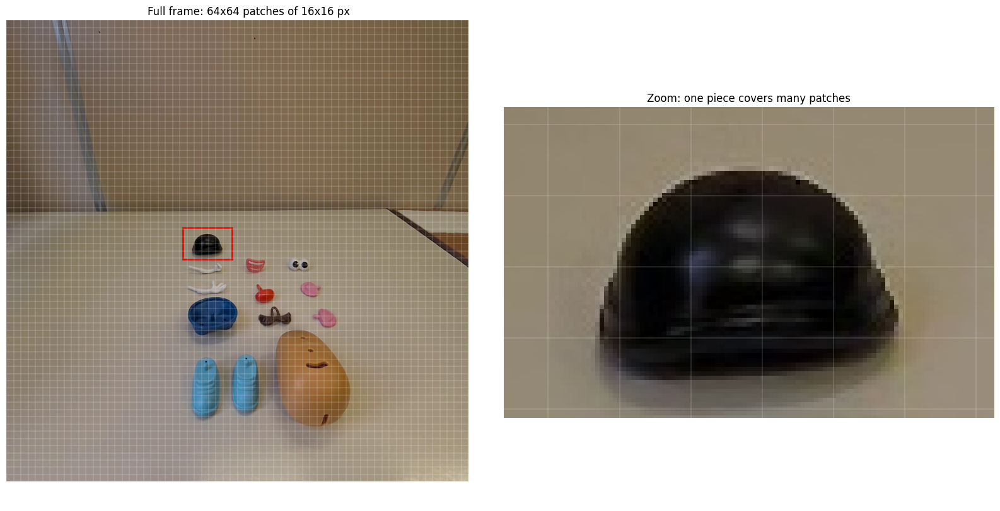

In [11]:
# 3.5 Patch grid
# What is a patch from a visual point of view. 
# A piece covers a lot of patches
# The edge patches are mixed
ZOOM_BOX = (390, 460, 500, 530)  # (x0, y0, x1, y1) in model-input pixels: adjust to frame one piece

example_resized = example_image.resize(example_resized_size, Image.Resampling.LANCZOS)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
for ax in axes:
    ax.imshow(example_resized)
    for x in range(0, example_resized_size[0] + 1, PATCH_SIZE):
        ax.axvline(x, color="white", linewidth=0.3, alpha=0.6)
    for y in range(0, example_resized_size[1] + 1, PATCH_SIZE):
        ax.axhline(y, color="white", linewidth=0.3, alpha=0.6)
    ax.axis("off")

x0, y0, x1, y1 = ZOOM_BOX
axes[0].add_patch(mpatches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor="red", linewidth=2))
axes[0].set_title(f"Full frame: {w_patches}x{h_patches} patches of {PATCH_SIZE}x{PATCH_SIZE} px")
axes[1].set_xlim(x0, x1)
axes[1].set_ylim(y1, y0)  # image y axis points down
axes[1].set_title("Zoom: one piece covers many patches")
plt.tight_layout()
plt.show()

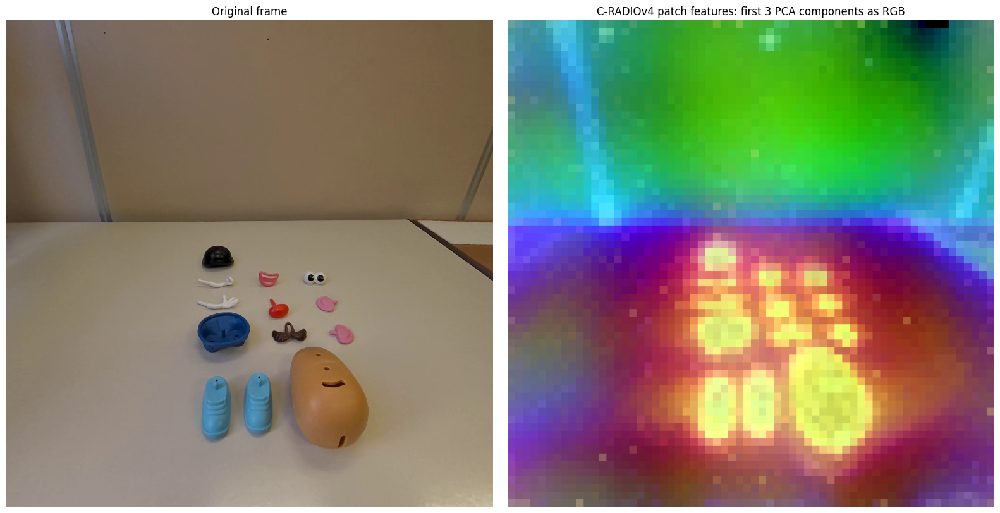

Variance explained by each component: [0.165 0.087 0.068] (total 31.9%)


In [12]:
# 3.6 Feature PCA
# Projection of the 1152 dimension on 3 to visualize them as RGB
def pca_to_rgb(features, border=PCA_BORDER_EXCLUDE, clip=PCA_CLIP_PERCENTILES, seed=RANDOM_SEED):
    """Project patch features onto their first 3 principal components and map them to RGB.
    Visualization only: the classifier always uses the full D-dimensional features."""
    h, w, d = features.shape
    fit_on = features[border:h - border, border:w - border].reshape(-1, d)
    pca = PCA(n_components=PCA_N_COMPONENTS, random_state=seed).fit(fit_on)
    projected = pca.transform(features.reshape(-1, d))
    low, high = np.percentile(projected, clip, axis=0)
    rgb = np.clip((projected - low) / (high - low + 1e-8), 0, 1)
    return rgb.reshape(h, w, 3), pca.explained_variance_ratio_


pca_rgb, explained = pca_to_rgb(example_features)
pca_rgb_full = cv2.resize(pca_rgb, example_image.size, interpolation=cv2.INTER_NEAREST)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
axes[0].imshow(example_image)
axes[0].set_title("Original frame")
axes[1].imshow(pca_rgb_full)
axes[1].set_title("C-RADIOv4 patch features: first 3 PCA components as RGB")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

print(f"Variance explained by each component: {explained.round(3)} (total {explained.sum():.1%})")

Observation 3.6: The first three components separate background (wall, table) from objects, but they explain only 31.9% of the variance. Differences between pieces live in the remaining dimensions, which is why classification uses all 1152 dimensions and not the PCA. The dark patch in the top-right corner is a border artifact: this is why border patches are excluded from the PCA fit (confirmed by the norm analysis in A.2).

References Section 3: 

C-RADIOv4 tech report Model and extraction 3.1-3.4; 

Dosovitskiy et al. 2021, An Image is Worth 16x16 Words (ViT) Patch Grid 3.5;

Oquab et al. 2024, DINOv2 + C-RADIOv4 tech report for PCA as standard visualization 3.6;



## Section 4 - Dataset

Stratified selection of reference frames based on explicit variable factors: assembled, partially assembled, disassembled, seen from above, base from two poses, hands.

4.1 Reference frames. The reference frames are the support set (Snell et al. 2017): the few annotated examples the prototypes are built from. Each frame declares which classes it provides (use_labels). Annotated polygons with other labels are ignored, not counted as background. The old shoe/pants labels are always ignored: base is only annotated when feet and pants are mounted together.

In [ ]:
# 4.1 Reference frames
# Each reference frame declares which classes it contributes to the prototypes.
# Annotated polygons with any other label are ignored (neither used nor counted as background).
REFERENCE_FRAMES = [
    {"frame": "5_assembled_f0002",            "role": "assembled",                   "use_labels": PIECE_LABELS},
    {"frame": "caos_f0149",                   "role": "partially assembled",         "use_labels": PIECE_LABELS},
    {"frame": "5_assembled_f0019",            "role": "assembled, 3/4 view",         "use_labels": PIECE_LABELS},
    {"frame": "3_disassembled_ordered_f0001", "role": "disassembled",                "use_labels": PIECE_LABELS - {"base"}},
    {"frame": "2_disassembled_caos_f0016",    "role": "disassembled, top-down view", "use_labels": PIECE_LABELS - {"base"}},
    {"frame": "Take_3_1_Base_f0099",          "role": "base only, upright",          "use_labels": {"base"}},
    {"frame": "Take_3_1_Base_f0131",          "role": "base only, lying",            "use_labels": {"base"}},
    {"frame": "caos_f0211",                   "role": "hands",                       "use_labels": {HAND_LABEL}},
    
]


for ref in REFERENCE_FRAMES:
    ref["image_path"] = FRAMES_DIR / f"{ref['frame']}.jpg"
    ref["json_path"] = FRAMES_DIR / f"{ref['frame']}.json"
    ref["sequence"] = sequence_of(ref["frame"])

In [14]:
# 4.2 Annotation check
# Automatic verification of file, dimensions and labels
# The table documents where each prototype comes from.
rows = []
for ref in REFERENCE_FRAMES:
    annotated = check_annotation(ref["image_path"], ref["json_path"])

    ref["used_labels"] = annotated & ref["use_labels"]
    rows.append({
        "frame": ref["frame"],
        "sequence": ref["sequence"],
        "role": ref["role"],
        "used": ", ".join(sorted(ref["used_labels"])),
        "ignored": ", ".join(sorted(annotated - ref["use_labels"])) or "-",
    })

display(pd.DataFrame(rows))

print("\nFrames contributing to each class:")
for label in sorted(PIECE_LABELS | {HAND_LABEL}):
    frames = [ref["frame"] for ref in REFERENCE_FRAMES if label in ref["used_labels"]]
    print(f"  {label:<10} {len(frames)} frame(s): {', '.join(frames) if frames else '— NONE'}")

,frame,sequence,role,used,ignored
0,5_assembled_f0002,5_assembled,assembled,"arm_1, arm_2, base, body, ear, eyes, hat, mous...",-
1,caos_f0149,caos,partially assembled,"arm_1, base, body, ear, eyes, hat, moustache, ...",-
2,3_disassembled_ordered_f0001,3_disassembled_ordered,disassembled,"arm_1, arm_2, body, ear, eyes, hat, moustache,...","pants, shoe"
3,2_disassembled_caos_f0016,2_disassembled_caos,"disassembled, top-down view","arm_1, arm_2, body, ear, eyes, hat, moustache,...","pants, shoe"
4,Take_3_1_Base_f0099,Take_3_1_Base,"base only, upright",base,-
5,Take_3_1_Base_f0131,Take_3_1_Base,"base only, lying",base,-
6,caos_f0211,caos,hands,hand,"body, ear, eyes, hat, moustache, nose, pants, ..."



Frames contributing to each class:
  arm_1      4 frame(s): 5_assembled_f0002, caos_f0149, 3_disassembled_ordered_f0001, 2_disassembled_caos_f0016
  arm_2      3 frame(s): 5_assembled_f0002, 3_disassembled_ordered_f0001, 2_disassembled_caos_f0016
  base       4 frame(s): 5_assembled_f0002, caos_f0149, Take_3_1_Base_f0099, Take_3_1_Base_f0131
  body       4 frame(s): 5_assembled_f0002, caos_f0149, 3_disassembled_ordered_f0001, 2_disassembled_caos_f0016
  ear        4 frame(s): 5_assembled_f0002, caos_f0149, 3_disassembled_ordered_f0001, 2_disassembled_caos_f0016
  eyes       4 frame(s): 5_assembled_f0002, caos_f0149, 3_disassembled_ordered_f0001, 2_disassembled_caos_f0016
  hand       1 frame(s): caos_f0211
  hat        4 frame(s): 5_assembled_f0002, caos_f0149, 3_disassembled_ordered_f0001, 2_disassembled_caos_f0016
  moustache  4 frame(s): 5_assembled_f0002, caos_f0149, 3_disassembled_ordered_f0001, 2_disassembled_caos_f0016
  mouth      4 frame(s): 5_assembled_f0002, caos_f0149, 3_d

Observation 4.2: Every piece class is covered by 4 reference frames, except arm_2 (3 frames: only one arm is visible in caos_f0149) and hand (1 frame).

In [15]:
# 4.3 Sequence split against temporal data leakage.
# Validation: errors are inspected and the method is tuned here (support-set and margin studies).
# Test: held out, never read by this notebook; used once, at the end of all studies.
# assembly_1 was inspected once, in the qualitative evaluation of v1-baseline (git tag), before any change.
VALIDATION_SEQUENCES = {"assembly_2", "1_disassembled_controlled_caos"}
TEST_SEQUENCES = {"assembly_1"}
assert not VALIDATION_SEQUENCES & TEST_SEQUENCES, "A sequence cannot be both validation and test"

reference_sequences = {ref["sequence"] for ref in REFERENCE_FRAMES}
leaked = reference_sequences & (VALIDATION_SEQUENCES | TEST_SEQUENCES)
assert not leaked, f"Data leakage: {leaked} used both for prototypes and for evaluation"

print("Prototype sequences :", sorted(reference_sequences))
print("Validation sequences:", sorted(VALIDATION_SEQUENCES))
print("Test sequences      :", sorted(TEST_SEQUENCES), "(held out, not read here)")

# Validation frames: stratified by assembly stage (never used for prototypes)
VALIDATION_FRAMES = [
    {"frame": "assembly_2_f0003", "stage": "all pieces loose"},
    {"frame": "assembly_2_f0017", "stage": "body on base"},
    {"frame": "assembly_2_f0046", "stage": "face (eyes, nose, moustache, mouth)"},
    {"frame": "assembly_2_f0057", "stage": "ears mounted"},
    {"frame": "assembly_2_f0068", "stage": "arms mounted"},
    {"frame": "assembly_2_f0030", "stage": "hands: piece held in hand"},
    {"frame": "1_disassembled_controlled_caos_f0001", "stage": "disassembled, front view"},
    {"frame": "1_disassembled_controlled_caos_f0016", "stage": "disassembled, side view"},
]
for val in VALIDATION_FRAMES:
    val["image_path"] = FRAMES_DIR / f"{val['frame']}.jpg"
    val["sequence"] = sequence_of(val["frame"])
    assert val["image_path"].exists(), f"Missing validation frame: {val['image_path']}"
    assert val["sequence"] in VALIDATION_SEQUENCES, f"{val['frame']} is not from a validation sequence"

print(f"{len(VALIDATION_FRAMES)} validation frames from sequences: {sorted({v['sequence'] for v in VALIDATION_FRAMES})}")


Prototype sequences : ['2_disassembled_caos', '3_disassembled_ordered', '5_assembled', 'Take_3_1_Base', 'caos']
Validation sequences: ['1_disassembled_controlled_caos', 'assembly_2']
Test sequences      : ['assembly_1'] (held out, not read here)
8 validation frames from sequences: ['1_disassembled_controlled_caos', 'assembly_2']


Limitation: in 1_disassembled_controlled_caos pants and shoes are separated, so base appears outside its definition (always mounted). Base results on this sequence are not meaningful. The sequence is kept for validation of the other loose pieces.

References Section 4: 

Snell et al. - 2017 - Prototypical Networks for Few-shot Learning Reference Frames 4.1 

Sener et al. 2022 (Assembly101), Sec. 4.6; Schoonbeek et al. 2024 (IndustReal), Sec. 4.4 Sequence Split 4.3 



## Section 5 - From polygons to patch labels

Annotations are at pixel level, the model is at patch level: a conversion rule is needed.

5.1 Rasterization. 
The labelme polygons are converted into a pixel map: each pixel holds the id of its class, 0 if it is not inside any polygon (background), or IGNORE_ID if its polygon belongs to a class the frame must not provide (e.g. old shoe/pants). Ignored pixels are neither piece nor background, so they cannot contaminate the background prototype. Mounted pieces overlap: the eyes polygon lies inside the body polygon, so the eye pixels belong to both. Polygons are painted from the largest to the smallest, like layers of paint: the body first, the eyes on top. The eye pixels therefore get the label eyes, whatever the order of annotation in labelme. The map is then resized to the model input resolution (nearest neighbour, so class ids are not mixed), aligned with the C-RADIO patch grid.

5.2 Patch labelling. Each 16x16 patch gets one label from the pixel map. A patch gets a piece label if that piece holds the absolute majority of its pixels (coverage ≥ MIN_LABEL_COVERAGE = 0.5). It is background only if it is 100% unannotated. All other patches (mixed boundary patches, ignored polygons) are ignored, like the void label in PASCAL VOC and Cityscapes. A simpler alternative, the center-pixel rule, uses one pixel out of 256 to decide the label of the whole patch (compared in 5.3 and A.3).

In [16]:
# 5.3 Applying to frames and threshold analysis 
for ref in REFERENCE_FRAMES:
    with Image.open(ref["image_path"]) as img:
        ref["resized_size"] = extractor.input_size(img.width, img.height)
    ref["pixel_map"] = rasterize_annotation(ref["json_path"], ref["use_labels"], ref["resized_size"])
    ref["patch_labels"], ref["patch_fractions"] = patch_label_grid(ref["pixel_map"], PATCH_SIZE, MIN_LABEL_COVERAGE)


def count_per_class(label_grids):
    ids, counts = np.unique(np.concatenate([g.ravel() for g in label_grids]), return_counts=True)
    return dict(zip(ids, counts))


center = PATCH_SIZE // 2
rules = {"center pixel": count_per_class(
    [ref["pixel_map"][center::PATCH_SIZE, center::PATCH_SIZE] for ref in REFERENCE_FRAMES])}
for threshold in (0.25, 0.5, 0.75):
    rules[f"coverage >= {threshold}"] = count_per_class(
        [patch_label_grid(ref["pixel_map"], PATCH_SIZE, threshold)[0] for ref in REFERENCE_FRAMES])

patch_counts = pd.DataFrame(rules).reindex(range(len(PATCH_LABEL_NAMES))).fillna(0).astype(int)
patch_counts.index = PATCH_LABEL_NAMES
display(patch_counts)

,center pixel,coverage >= 0.25,coverage >= 0.5,coverage >= 0.75
background,27209,26744,26744,26744
body,234,229,226,199
base,186,185,184,163
hat,37,38,38,25
eyes,25,24,24,14
ear,40,39,39,25
nose,26,23,23,13
moustache,28,27,27,17
mouth,21,21,20,10
arm_1,33,29,28,14


Observation 5.3: With the center-pixel rule, 465 mixed boundary patches would end up in the background prototype. Thresholds 0.25 and 0.5 give almost identical counts, because the majority rule already requires most of the patch to be the piece. At 0.75, small classes lose 42–55% of their patches (arm_2 11 → 5, mouth 20 → 10). We therefore use 0.5: every patch is at least half the piece, without emptying the small classes.

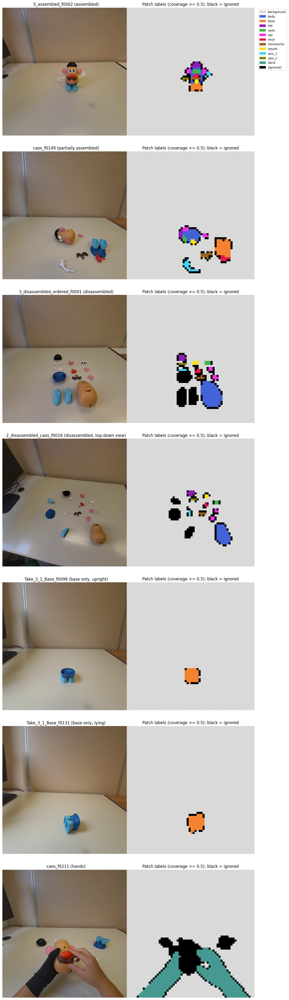

In [17]:
# 5.4 Visual Check
# on all reference frames: small pieces prevail over the body, mixed patches form a thin frame.
legend = [mpatches.Patch(color=CLASS_COLORS[n], label=n) for n in CLASS_NAMES] + \
         [mpatches.Patch(color="black", label="(ignored)")]

fig, axes = plt.subplots(len(REFERENCE_FRAMES), 2, figsize=(12, 6 * len(REFERENCE_FRAMES)))
for row, ref in zip(axes, REFERENCE_FRAMES):
    image = Image.open(ref["image_path"]).convert("RGB").resize(ref["resized_size"])
    label_rgb = cv2.resize(label_grid_to_rgb(ref["patch_labels"]), ref["resized_size"],
                           interpolation=cv2.INTER_NEAREST)
    row[0].imshow(image)
    row[0].set_title(f"{ref['frame']} ({ref['role']})")
    row[1].imshow(label_rgb)
    row[1].set_title(f"Patch labels (coverage >= {MIN_LABEL_COVERAGE}); black = ignored")
    for ax in row:
        ax.axis("off")

axes[0, 1].legend(handles=legend, bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

Observation 5.4: Every visible piece is either labelled or ignored (black): no piece leaked into the background. Mounted pieces prevail over the body. Limitation: thin pieces such as the arms produce mostly mixed patches, so they contribute fewer examples than their size suggests.

References Section 5:

PASCAL VOC (Everingham et al. 2010, The PASCAL Visual Object Classes (VOC) Challenge, IJCV) marks as "void" a thin band around the edge of each object, because the boundary pixels are ambiguous.

Cityscapes (Cordts et al. 2016, The Cityscapes Dataset for Semantic Urban Scene Understanding, CVPR) has "void" classes excluded from both training and evaluation.

Tools used: labelme: Kentaro Wada, labelme: Image Polygonal Annotation with Python, repository GitHub (wkentaro/labelme)
Russell et al. 2008, LabelMe: a database and web-based tool for image annotation, International Journal of Computer Vision

## Section 6 - Prototype construction and saving

One prototype per class: the normalized mean of its patch features (6.2). Prototypes are saved with their metadata for reuse (6.4).

In [18]:
# 6.1 Feature extraction for all reference frames
for ref in REFERENCE_FRAMES:
    image = Image.open(ref["image_path"]).convert("RGB")
    ref["features"], resized_size = extractor.extract(image)
    assert resized_size == ref["resized_size"], f"Resolution mismatch in {ref['frame']}"
    assert ref["features"].shape[:2] == ref["patch_labels"].shape, f"Grid mismatch in {ref['frame']}"

print(f"Features extracted for {len(REFERENCE_FRAMES)} reference frames, "
      f"grid {ref['features'].shape[1]}x{ref['features'].shape[0]}, D = {ref['features'].shape[2]}")

Features extracted for 7 reference frames, grid 64x64, D = 1152


6.2 Prototype construction. Each patch vector is L2-normalized (only its direction is kept, since classification uses cosine similarity), all normalized patches of a class are pooled across the reference frames with the same weight (patch-weighted), and their mean is normalized again. This is the maximum-likelihood mean direction of a von Mises-Fisher distribution (Banerjee et al. 2005), the same procedure as weight imprinting (Qi et al. 2018). Ignored patches never enter any prototype.

In [19]:
# 6.2 Prototype construction: normalized mean, patch-weighted (build_prototypes in src/perception/prototypes.py)
prototypes, prototype_patch_counts = build_prototypes(REFERENCE_FRAMES)

missing = [name for name in CLASS_NAMES if name not in prototypes]
assert not missing, f"No patches for classes: {missing}"
print(f"{len(prototypes)} prototypes built, each a unit vector of dimension {len(next(iter(prototypes.values())))}")

12 prototypes built, each a unit vector of dimension 1152


In [20]:
# 6.3 Patches per class and per reference frame
count_table = pd.DataFrame(
    {ref["frame"]: [int((ref["patch_labels"] == i).sum()) for i in range(len(CLASS_NAMES))]
     for ref in REFERENCE_FRAMES},
    index=CLASS_NAMES,
)
count_table["total"] = count_table.sum(axis=1)
display(count_table)

,5_assembled_f0002,caos_f0149,3_disassembled_ordered_f0001,2_disassembled_caos_f0016,Take_3_1_Base_f0099,Take_3_1_Base_f0131,caos_f0211,total
background,3962,3850,3733,3858,4036,4017,3288,26744
body,20,40,109,57,0,0,0,226
base,20,59,0,0,47,58,0,184
hat,11,8,10,9,0,0,0,38
eyes,8,6,6,4,0,0,0,24
ear,11,11,10,7,0,0,0,39
nose,5,10,5,3,0,0,0,23
moustache,5,12,5,5,0,0,0,27
mouth,4,6,6,4,0,0,0,20
arm_1,5,16,4,3,0,0,0,28


Observation 6.3: Some classes are dominated by one frame: 57% of arm_1 patches come from caos_f0149, where the arm is close to the camera (patch-weighted mean). In the assembled frame the figure is small, so each piece gives only 4–11 patches. arm_2 is the poorest class (11 patches from 3 frames); hand has 482 patches but from a single frame.
The number of patches does not give a class more weight in classification (every prototype is a unit vector), but fewer patches make the prototype less representative.

In [21]:
# 6.4 Save prototypes and metadata, so other notebooks (e.g. the margin study) can reuse them
prototype_names = [name for name in CLASS_NAMES if name in prototypes]
metadata = {
    "created": time.strftime("%Y-%m-%d %H:%M"),
    "model": MODEL_DIR.name,
    "patch_size": PATCH_SIZE,
    "feature_dim": int(len(prototypes[prototype_names[0]])),
    "prototype_rule": "normalized mean of L2-normalized patch features, patch-weighted",
    "min_label_coverage": MIN_LABEL_COVERAGE,
    "reference_frames": [{"frame": r["frame"], "role": r["role"], "use_labels": sorted(r["use_labels"])}
                         for r in REFERENCE_FRAMES],
}

save_prototypes(PROTOTYPES_PATH, prototypes, prototype_patch_counts, metadata)

# Round-trip check: reload and compare
loaded = load_prototypes(PROTOTYPES_PATH)
assert loaded["class_names"] == prototype_names
assert np.allclose(loaded["prototypes"], np.stack([prototypes[name] for name in prototype_names]))
print(f"Saved {len(prototype_names)} prototypes to {PROTOTYPES_PATH}")


Saved 12 prototypes to c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\outputs\phase_1_perception\prototypes.npz


References Section 6:

Snell et al. 2017, Sec. 2.2: prototype = mean of examples;

Mensink et al. 2013: nearest class mean;

Banerjee et al. 2005, Unit Hypersphere: normalized mean as an estimate of the average direction von Mises-Fisher;

Qi et al. 2018: same procedure as weight imprinting;

Chen et al. 2019: frozen pre-trained features and simple classifier as strong baseline



Normalization, patch norms and the labelling rule are verified in Appendix A.

## Section 7 - Support-set gallery

How each class appears in each reference frame. Yellow: the annotated polygon (pixel level). Bright: the 16x16 patches that enter the prototype (patch level). Dimmed: background or ignored mixed patches.

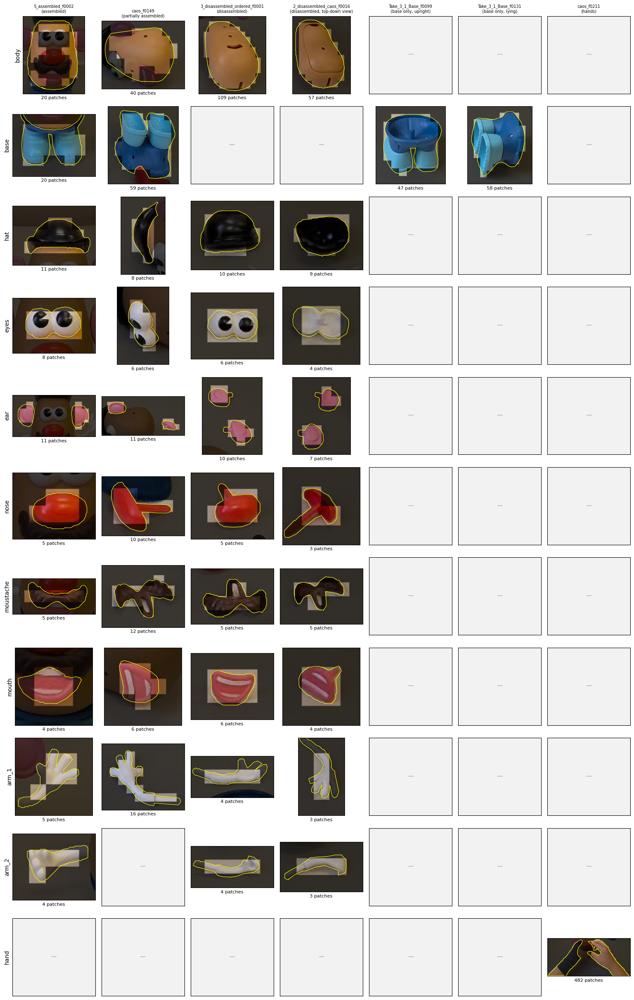

In [22]:
# 7.1 Support-set gallery: how each class appears in each reference frame.
# Rows = classes, columns = reference frames. Each crop shows the piece with the patches
# that enter its prototype at full brightness; everything else is dimmed.
gallery_classes = [name for name in CLASS_NAMES if name != BACKGROUND_LABEL]
resized_images = {
    ref["frame"]: np.asarray(Image.open(ref["image_path"]).convert("RGB").resize(ref["resized_size"]),
                             dtype=np.float32) / 255
    for ref in REFERENCE_FRAMES
}

fig, axes = plt.subplots(len(gallery_classes), len(REFERENCE_FRAMES),
                         figsize=(2.2 * len(REFERENCE_FRAMES), 2.2 * len(gallery_classes)))

annotations = {ref["frame"]: json.load(open(ref["json_path"])) for ref in REFERENCE_FRAMES}
for r, name in enumerate(gallery_classes):
    class_id = CLASS_NAMES.index(name)
    for c, ref in enumerate(REFERENCE_FRAMES):
        ax = axes[r, c]
        ax.set_xticks([])
        ax.set_yticks([])
        mask = ref["patch_labels"] == class_id

        if not mask.any():
            # This frame does not provide this class
            ax.set_facecolor("0.95")
            ax.text(0.5, 0.5, "—", ha="center", va="center", color="0.6", transform=ax.transAxes)
        else:
            # Crop: bounding box of the class patches, plus a margin (in patches)
            rows, cols = np.where(mask)
            h_p, w_p = mask.shape
            r0, r1 = max(rows.min() - GALLERY_MARGIN, 0), min(rows.max() + 1 + GALLERY_MARGIN, h_p)
            c0, c1 = max(cols.min() - GALLERY_MARGIN, 0), min(cols.max() + 1 + GALLERY_MARGIN, w_p)

            # Patch mask -> pixel mask; dim every pixel that is not in a prototype patch
            pixel_mask = np.kron(mask, np.ones((PATCH_SIZE, PATCH_SIZE)))[..., None]
            shown = resized_images[ref["frame"]] * np.where(pixel_mask, 1.0, GALLERY_DIM_FACTOR)
            ax.imshow(shown[r0 * PATCH_SIZE:r1 * PATCH_SIZE, c0 * PATCH_SIZE:c1 * PATCH_SIZE])
            ax.set_xlabel(f"{mask.sum()} patches", fontsize=8)
            # Overlay the original polygon outline (pixel-precise annotation) on the patch view
            ann = annotations[ref["frame"]]
            scale_x = ref["resized_size"][0] / ann["imageWidth"]
            scale_y = ref["resized_size"][1] / ann["imageHeight"]
            for shape in ann["shapes"]:
                if shape["label"] != name:
                    continue
                pts = np.array(shape["points"] + [shape["points"][0]])       # close the polygon
                ax.plot(pts[:, 0] * scale_x - c0 * PATCH_SIZE, pts[:, 1] * scale_y - r0 * PATCH_SIZE,
                        color="yellow", linewidth=0.8)
            ax.set_xlim(-0.5, (c1 - c0) * PATCH_SIZE - 0.5)
            ax.set_ylim((r1 - r0) * PATCH_SIZE - 0.5, -0.5)

        if r == 0:
            ax.set_title(f"{ref['frame']}\n({ref['role']})", fontsize=7)
        if c == 0:
            ax.set_ylabel(name, fontsize=10)

plt.tight_layout()
fig.savefig(OUTPUT_DIR / "support_set_gallery.png", dpi=200, bbox_inches="tight")
plt.show()

Observation 7.1: Each class appears in different states and viewpoints across the reference frames (stratified support set). In the assembled frame, mounted pieces are separated from the body, which is lit only between them (5.1). Thin pieces (arms, nose seen from above) contribute only their central patches: edges and fingers are mixed patches and are ignored. In the assembled frame the figure is small, so crops are low resolution and each piece covers few patches (6.3). In the assembled frame, arm_1 is represented mainly by its open hand: the thin forearm never covers half a patch.

References Section 7: none (visualization of the support set)

## Section 8 - Prototype similarity

How different the prototypes are from each other. Two classes with very similar prototypes are likely to be confused by the classifier (Section 9).

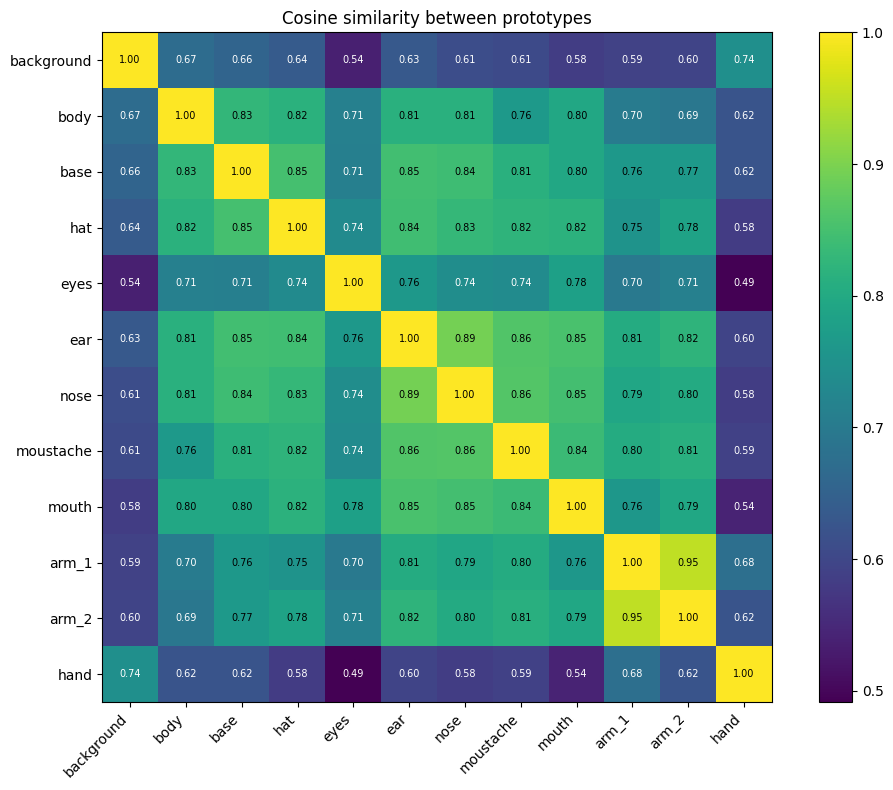

In [23]:
# 8.1 Prototype similarity matrix (cosine similarity between unit prototypes = dot product)
prototype_matrix = np.stack([prototypes[name] for name in prototype_names])
similarity = prototype_matrix @ prototype_matrix.T

off_diagonal = similarity[~np.eye(len(prototype_names), dtype=bool)]
vmin, vmax = off_diagonal.min(), 1.0
midpoint = (vmin + vmax) / 2

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(similarity, cmap="viridis", vmin=vmin, vmax=vmax)
ax.set_xticks(range(len(prototype_names)))
ax.set_xticklabels(prototype_names, rotation=45, ha="right")
ax.set_yticks(range(len(prototype_names)))
ax.set_yticklabels(prototype_names)
for i in range(len(prototype_names)):
    for j in range(len(prototype_names)):
        ax.text(j, i, f"{similarity[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="black" if similarity[i, j] > midpoint else "white")
fig.colorbar(im, ax=ax, fraction=0.046)
ax.set_title("Cosine similarity between prototypes")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "prototype_similarity.png", dpi=200, bbox_inches="tight")
plt.show()

Observation 8.1: The most similar pair is arm_1–arm_2 (0.95): same material and shape, only the hand differs. The small face pieces form a group (ear, nose, moustache, mouth: 0.84–0.89), with nose–ear as the closest pair despite different colors. Eyes are the most distinctive piece (nearest class at 0.78). Body and base are well separated (0.83). The background is far from all pieces (0.54–0.67) except hand (0.74), a harmless confusion since hand is never reported as a piece. All piece prototypes share a high baseline similarity (0.70–0.89): relative differences matter, not absolute values.

In [24]:
# 8.2 For each class: its nearest other class
nearest_similarity = similarity.copy()
np.fill_diagonal(nearest_similarity, -np.inf)

rows = []
for i, name in enumerate(prototype_names):
    j = int(nearest_similarity[i].argmax())
    rows.append({"class": name, "nearest class": prototype_names[j],
                 "cosine": similarity[i, j], "distance (1 - cosine)": 1 - similarity[i, j]})
nearest_table = pd.DataFrame(rows).set_index("class").sort_values("cosine", ascending=False)
display(nearest_table.round(4))

,nearest class,cosine,distance (1 - cosine)
class,,,
arm_1,arm_2,0.9504,0.0496
arm_2,arm_1,0.9504,0.0496
nose,ear,0.8932,0.1068
ear,nose,0.8932,0.1068
moustache,nose,0.8644,0.1356
mouth,ear,0.8534,0.1466
base,hat,0.8504,0.1496
hat,base,0.8504,0.1496
body,base,0.8286,0.1714


Observation 8.2: The risky pairs for Section 9 are arm_1–arm_2 and the face-piece group. These are confusions between pieces, which the background margin does not address.

References Section 8: no new reference. Distance-based classification with class prototypes (Snell et al. 2017; Mensink et al. 2013, already cited in Section 6) implies that classes with close prototypes are the most likely to be confused: this analysis measures that closeness.

## Section 9 - Classifier 

Nearest-prototype classification with cosine similarity, plus background rejection. One single function, used for validation frames (Section 10) and video (Section 11).

9.1 Classifier. Each patch feature is L2-normalized and compared with the 12 prototypes by cosine similarity (a dot product, since prototypes are unit vectors). The patch takes the most similar prototype (nearest class mean, Mensink et al. 2013; Snell et al. 2017). Background rejection: if the winner is not background but its similarity exceeds the background similarity by less than CONFIDENCE_MARGIN (0.03, provisional, studied in a dedicated notebook), the patch is assigned to background. The margin decides only piece vs background, never between two pieces (8.2). Border artifacts (A.2) are not filtered: Section 10.2 shows they are always classified as background.

In [25]:
# 9.1 Classifier: nearest prototype (cosine similarity) + background rejection margin
# (classify_patches in src/perception/prototypes.py)
assert prototype_names == CLASS_NAMES, "Prototype order must match CLASS_NAMES (colors, indices)"


9.2 Validation frames. The 8 validation frames (4.3) are classified and their raw similarities saved. The margin study can then test any margin value without running C-RADIO again.

In [26]:
# 9.2 Classify all validation frames and save raw similarities for the margin study
validation_results = {}
for val in VALIDATION_FRAMES:
    image = Image.open(val["image_path"]).convert("RGB")
    features, resized_size = extractor.extract(image)
    labels, similarities = classify_patches(features, prototype_matrix, CONFIDENCE_MARGIN)
    validation_results[val["frame"]] = {
        "labels": labels,
        "similarities": similarities,
        "norms": np.linalg.norm(features, axis=-1),   # kept for the border-artifact check (A.2)
        "resized_size": resized_size,
    }

np.savez_compressed(
    OUTPUT_DIR / "validation_similarities.npz",
    class_names=np.array(CLASS_NAMES),
    frames=np.array([v["frame"] for v in VALIDATION_FRAMES]),
    **{f"{frame}__similarities": r["similarities"].astype(np.float32) for frame, r in validation_results.items()},
    **{f"{frame}__norms": r["norms"].astype(np.float32) for frame, r in validation_results.items()},
)

summary = pd.DataFrame({
    v["frame"]: {name: int((validation_results[v["frame"]]["labels"] == i).sum()) for i, name in enumerate(CLASS_NAMES)}
    for v in VALIDATION_FRAMES
}).T
display(summary)


,background,body,base,hat,eyes,ear,nose,moustache,mouth,arm_1,arm_2,hand
assembly_2_f0003,3785,51,77,27,14,14,30,15,1,15,22,45
assembly_2_f0017,3812,79,46,28,15,19,35,17,7,21,17,0
assembly_2_f0046,3775,44,40,27,18,19,8,3,10,27,20,105
assembly_2_f0057,3771,32,37,32,18,29,6,7,8,22,28,106
assembly_2_f0068,3626,32,41,31,15,27,7,4,11,9,28,265
assembly_2_f0030,3429,69,35,24,17,16,17,9,11,0,11,458
1_disassembled_controlled_caos_f0001,3829,97,27,34,4,38,7,15,5,3,37,0
1_disassembled_controlled_caos_f0016,3803,92,23,36,0,34,6,11,1,0,29,61


Observation 9.2: Counts per class, a first coarse check. Hand is found when hands are in the frame (45–458 patches) and absent otherwise (0 in assembly_2_f0017 and 1_disassembled_controlled_caos_f0001). The 61 hand patches of 1_disassembled_controlled_caos_f0016 are jeans (10.1). In 1_disassembled_controlled_caos arm_2 gets far more patches than arm_1 (37 vs 3, 29 vs 0) and eyes get few or none (4, 0): loose arms and eyes are predicted as arm_2 (10.1).

References Section 9: nearest class mean classification (Mensink et al. 2013; Snell et al. 2017, already cited in Section 6). The background rejection margin is provisional and studied in a dedicated notebook, where its literature is discussed.

## Section 10 - Qualitative evaluation on validation frames
Predicted patch labels on the 8 validation frames (4.3), from sequences never used for prototypes. Qualitative only: the quantitative evaluation (per-class IoU on annotated frames) is done in the support-set and margin studies. The test sequence (assembly_1) is not read in this notebook.

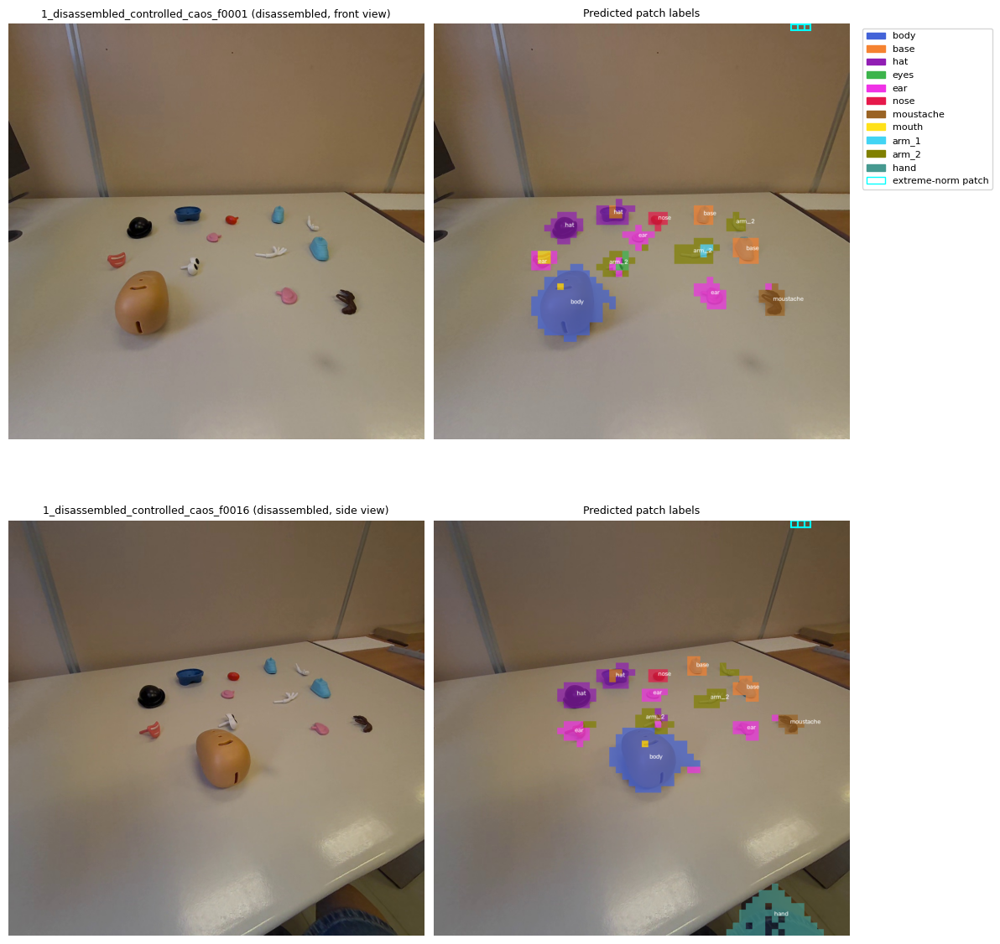

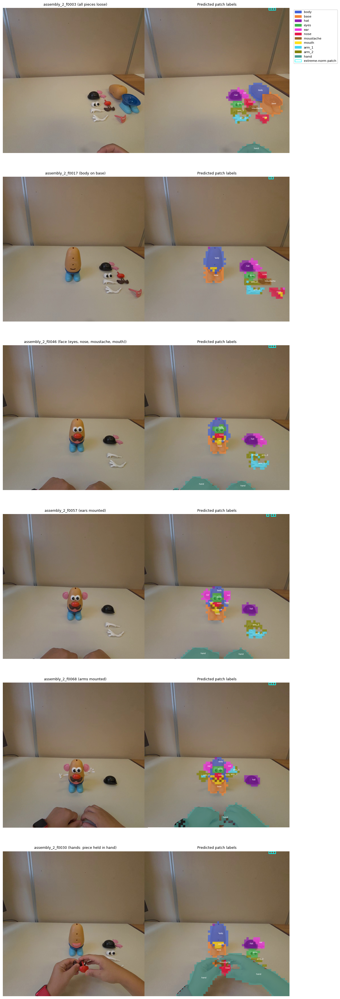

In [27]:
# 10.1 Predicted patch labels on the validation frames, one figure per validation sequence.
# render_overlay is in src/perception/visualization.py
# Cyan squares: extreme-norm patches (border artifacts, A.2).
legend = [mpatches.Patch(color=CLASS_COLORS[n], label=n) for n in CLASS_NAMES if n != BACKGROUND_LABEL] + \
         [mpatches.Patch(facecolor="none", edgecolor="cyan", label="extreme-norm patch")]

for sequence in sorted(VALIDATION_SEQUENCES):
    vals = [v for v in VALIDATION_FRAMES if v["sequence"] == sequence]
    fig, axes = plt.subplots(len(vals), 2, figsize=(12, 6 * len(vals)), squeeze=False)
    for (ax_image, ax_pred), val in zip(axes, vals):
        result = validation_results[val["frame"]]
        image = np.asarray(Image.open(val["image_path"]).convert("RGB").resize(result["resized_size"]))

        ax_image.imshow(image)
        ax_image.set_title(f"{val['frame']} ({val['stage']})", fontsize=9)
        ax_pred.imshow(render_overlay(image, result["labels"], MIN_BLOB_PATCHES))
        ax_pred.set_title("Predicted patch labels", fontsize=9)

        extreme = np.argwhere(result["norms"] > EXTREME_NORM_FACTOR * np.median(result["norms"]))
        for r, c in extreme:
            ax_pred.add_patch(mpatches.Rectangle((c * PATCH_SIZE, r * PATCH_SIZE), PATCH_SIZE, PATCH_SIZE,
                                                 fill=False, edgecolor="cyan", linewidth=1.5))
        for ax in (ax_image, ax_pred):
            ax.axis("off")

    axes[0, 1].legend(handles=legend, bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
    plt.tight_layout()
    fig.savefig(OUTPUT_DIR / f"validation_predictions_{sequence}.png", dpi=150, bbox_inches="tight")
    plt.show()

Observation 10.1:
No false positives on wall or table in any validation frame. Predicted pieces are slightly larger than the real ones: mixed boundary patches, ignored when building prototypes, are assigned to the piece at inference. The assembly is followed at every stage of assembly_2: body, base, hat, eyes, nose, moustache, mouth and ears are recognized when mounted, and hands are recognized. Pieces held in hand keep their class (nose and moustache, f0030).
Errors. Arms are mixed between arm_1 and arm_2, both loose and mounted (f0046, f0057, f0068); in 1_disassembled_controlled_caos they are mostly arm_2. A mouth lying on its side is predicted as nose in assembly_2 (f0003, f0017) and as ear in 1_disassembled_controlled_caos. Loose eyes in 1_disassembled_controlled_caos are predicted mostly as arm_2. The empty mouth slot on the body is predicted as mouth, both with the body on the base (f0017) and with the body lying alone (1_disassembled_controlled_caos). Jeans at the bottom of the frame are predicted as hand (f0016), harmless since hand is never reported as a piece. Separated pants are predicted as hat and shoes as base, as they fall outside the base definition.

In [28]:
# 10.2 Are extreme-norm patches classified as pieces? (border artifacts, A.2)
rows = []
for val in VALIDATION_FRAMES:
    result = validation_results[val["frame"]]
    extreme = result["norms"] > EXTREME_NORM_FACTOR * np.median(result["norms"])
    predicted = [CLASS_NAMES[i] for i in result["labels"][extreme]]
    rows.append({
        "frame": val["frame"],
        "extreme patches": int(extreme.sum()),
        "positions": np.argwhere(extreme).tolist(),
        "predicted as": ", ".join(predicted) or "-",
    })
display(pd.DataFrame(rows).set_index("frame"))

,extreme patches,positions,predicted as
frame,,,
assembly_2_f0003,3,"[[0, 55], [0, 56], [0, 57]]","background, background, background"
assembly_2_f0017,2,"[[0, 55], [0, 56]]","background, background"
assembly_2_f0046,3,"[[0, 55], [0, 56], [0, 57]]","background, background, background"
assembly_2_f0057,3,"[[0, 54], [0, 56], [0, 57]]","background, background, background"
assembly_2_f0068,3,"[[0, 55], [0, 56], [0, 57]]","background, background, background"
assembly_2_f0030,3,"[[0, 55], [0, 56], [0, 57]]","background, background, background"
1_disassembled_controlled_caos_f0001,3,"[[0, 55], [0, 56], [0, 57]]","background, background, background"
1_disassembled_controlled_caos_f0016,3,"[[0, 55], [0, 56], [0, 57]]","background, background, background"


Observation 10.2:
The extreme-norm border patches (A.2) are classified as background in all 8 validation frames: they cause no false positives, so no filtering is needed. They lie in the first row, columns 54–57.

In [42]:
# 10.3 Mouth on the empty slot: top1-top2 confidence
# Only mouth blobs touching body patches are measured: a loose mouth lying on the table is excluded.
MOUTH_ID, BODY_ID = CLASS_NAMES.index("mouth"), CLASS_NAMES.index("body")
EMPTY_SLOT_FRAME = "assembly_2_f0017"                                           # body on base, mouth not mounted yet
MOUNTED_MOUTH_FRAMES = ["assembly_2_f0046", "assembly_2_f0057", "assembly_2_f0068"]  # mouth mounted

from scipy import ndimage


def mouth_on_body(labels):
    """Patches predicted as mouth, in blobs that touch patches predicted as body."""
    blobs, _ = ndimage.label(labels == MOUTH_ID)
    near_body = ndimage.binary_dilation(labels == BODY_ID)
    keep = np.unique(blobs[near_body & (blobs > 0)])
    return np.isin(blobs, keep)

# Mouth predicted on the empty mouth slot: how close are mouth and body for those patches?
result = validation_results[EMPTY_SLOT_FRAME]
mouth_patches = mouth_on_body(result["labels"])
print(f"{EMPTY_SLOT_FRAME}: {mouth_patches.sum()} mouth patches touching the body")
if mouth_patches.any():
    sims = result["similarities"][mouth_patches]
    print(f"  mean similarity to mouth: {sims[:, MOUTH_ID].mean():.3f}")
    print(f"  mean similarity to body:  {sims[:, BODY_ID].mean():.3f}")
    print(f"  mean gap mouth - body:    {(sims[:, MOUTH_ID] - sims[:, BODY_ID]).mean():.3f}")

# Gap between the best and the second-best class for patches predicted as mouth:
# empty slot vs real mounted mouth
for frame in [EMPTY_SLOT_FRAME] + MOUNTED_MOUTH_FRAMES:
    result = validation_results[frame]
    mouth_patches = mouth_on_body(result["labels"])
    if not mouth_patches.any():
        print(f"{frame}: no patch predicted as mouth")
        continue
    sims = np.sort(result["similarities"][mouth_patches], axis=1)
    gap = sims[:, -1] - sims[:, -2]                     # best minus second best
    print(f"{frame}: {mouth_patches.sum():2d} mouth patches, "
          f"top1-top2 gap mean {gap.mean():.3f} (min {gap.min():.3f}, max {gap.max():.3f})")


assembly_2_f0017: 4 mouth patches touching the body
  mean similarity to mouth: 0.797
  mean similarity to body:  0.742
  mean gap mouth - body:    0.055
assembly_2_f0017:  4 mouth patches, top1-top2 gap mean 0.055 (min 0.018, max 0.093)
assembly_2_f0046: 10 mouth patches, top1-top2 gap mean 0.074 (min 0.010, max 0.162)
assembly_2_f0057:  7 mouth patches, top1-top2 gap mean 0.084 (min 0.013, max 0.171)
assembly_2_f0068:  3 mouth patches, top1-top2 gap mean 0.024 (min 0.021, max 0.027)


Observation 10.3: Only mouth patches touching the body are measured: in f0017 a loose mouth on the table is also partly predicted as mouth. On the empty slot (f0017, 4 patches) mouth wins over body by 0.055 on average. The top1–top2 gap is 0.055 on the empty slot and 0.074, 0.084 and 0.024 on the mounted mouth (f0046, f0057, f0068). In f0068 only 3 patches on the body are predicted as mouth. The empty slot falls inside the range of the mounted mouth, and the patch ranges overlap widely (0.018–0.093 vs 0.010–0.171). On validation, a top1–top2 gap does not separate the empty slot from a mounted mouth.

References Section 10: no new reference. Validation frames come from sequences never used for prototypes (split by recording, Section 4.3: Sener et al. 2022; Schoonbeek et al. 2024). The test sequence is held out until the end of all studies.

## Section 11 - Video pipeline (motion gating)

C-RADIO runs once each time the scene becomes still (MOTION_THRESHOLD, STABLE_FRAMES_NEEDED: provisional, this gating will be replaced by continuous perception). The prediction is shown only while the scene stays still. The full video is saved in the outputs folder; the notebook shows one snapshot per C-RADIO run.

Motion score: mean absolute grey-level difference between consecutive frames, downscaled to 320x320. An earlier version used only the central 50% of the frame, checked only qualitatively; neither version is validated, and the gating is provisional.

In [30]:
# 11.1 Motion score (render_overlay is in src/perception/visualization.py)
def motion_score(prev_gray, gray):
    """Mean absolute grey-level difference (0-255) between two consecutive downscaled frames."""
    return float(np.abs(gray.astype(np.float32) - prev_gray.astype(np.float32)).mean())

In [31]:
# 11.2 Video pipeline: C-RADIO runs once each time the scene becomes still
DEMO_VIDEO = VIDEOS_DIR / "assembly_2.mp4"
assert DEMO_VIDEO.stem in VALIDATION_SEQUENCES, "The demo video must come from a validation sequence"

cap = cv2.VideoCapture(str(DEMO_VIDEO))
fps = cap.get(cv2.CAP_PROP_FPS)
width, height = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
output_video = OUTPUT_DIR / f"{DEMO_VIDEO.stem}_perception.mp4"
writer = cv2.VideoWriter(str(output_video), cv2.VideoWriter_fourcc(*"mp4v"), fps, (width, height))

prev_gray, still_count, current_labels = None, 0, None
video_log, snapshots = [], []
frame_index = 0
while True:
    ok, frame_bgr = cap.read()
    if not ok:
        break
    frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
    gray = cv2.resize(cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2GRAY), MOTION_SIZE)
    score = motion_score(prev_gray, gray) if prev_gray is not None else np.inf
    still_count = still_count + 1 if score < MOTION_THRESHOLD else 0
    prev_gray = gray

    if still_count == STABLE_FRAMES_NEEDED:          # the scene has just become still: run C-RADIO once
        features, _ = extractor.extract(Image.fromarray(frame_rgb))
        current_labels, _ = classify_patches(features, prototype_matrix, CONFIDENCE_MARGIN)
        counts = {CLASS_NAMES[i]: int((current_labels == i).sum()) for i in range(len(CLASS_NAMES))}
        video_log.append({
            "frame": frame_index,
            "time (s)": round(frame_index / fps, 2),
            "pieces seen": ", ".join(n for n, c in counts.items()
                                     if n not in (BACKGROUND_LABEL, HAND_LABEL) and c >= MIN_BLOB_PATCHES),
        })
        snapshots.append((frame_index, render_overlay(frame_rgb, current_labels, MIN_BLOB_PATCHES)))
    elif still_count < STABLE_FRAMES_NEEDED:
        current_labels = None                        # moving: no prediction is shown

    shown = render_overlay(frame_rgb, current_labels, MIN_BLOB_PATCHES) if current_labels is not None else frame_rgb.copy()
    status = "STILL - perception active" if current_labels is not None else "MOVING"
    cv2.putText(shown, status, (20, 40), cv2.FONT_HERSHEY_SIMPLEX, 1.0, (255, 255, 255), 2, cv2.LINE_AA)
    writer.write(cv2.cvtColor(shown, cv2.COLOR_RGB2BGR))
    frame_index += 1

cap.release()
writer.release()
print(f"{frame_index} frames processed, C-RADIO run {len(video_log)} times. Video saved to {output_video}")
pd.set_option("display.max_colwidth", None)
display(pd.DataFrame(video_log))

2444 frames processed, C-RADIO run 33 times. Video saved to c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\outputs\phase_1_perception\assembly_2_perception.mp4


,frame,time (s),pieces seen
0,5,0.17,"body, base, hat, eyes, ear, nose, moustache, arm_1, arm_2"
1,58,1.93,"body, base, hat, eyes, ear, nose, moustache, arm_1, arm_2"
2,71,2.37,"body, base, hat, eyes, ear, nose, moustache, arm_1, arm_2"
3,190,6.33,"body, base, hat, eyes, ear, nose, moustache, arm_1, arm_2"
4,205,6.83,"body, base, hat, eyes, ear, nose, moustache, arm_1, arm_2"
5,265,8.83,"body, base, hat, eyes, ear, nose, moustache, arm_1, arm_2"
6,372,12.40,"body, base, ear, arm_1"
7,453,15.10,"body, base, hat, eyes, ear, nose, moustache, mouth, arm_1, arm_2"
8,465,15.50,"body, base, hat, eyes, ear, nose, moustache, mouth, arm_1, arm_2"
9,615,20.50,"body, base, hat, eyes, ear, nose, moustache, mouth, arm_2"


Observation 11.2: In about 81 s of video (2444 frames at 30 fps), C-RADIO runs 33 times. Close triggers in the same state (e.g. frames 2199, 2205, 2226) come from short movements between pauses. The "pieces seen" column lists almost every class at every run, because loose pieces on the table are counted too: telling mounted from loose pieces requires their position relative to the body, which is the task of the next phase (state machine).

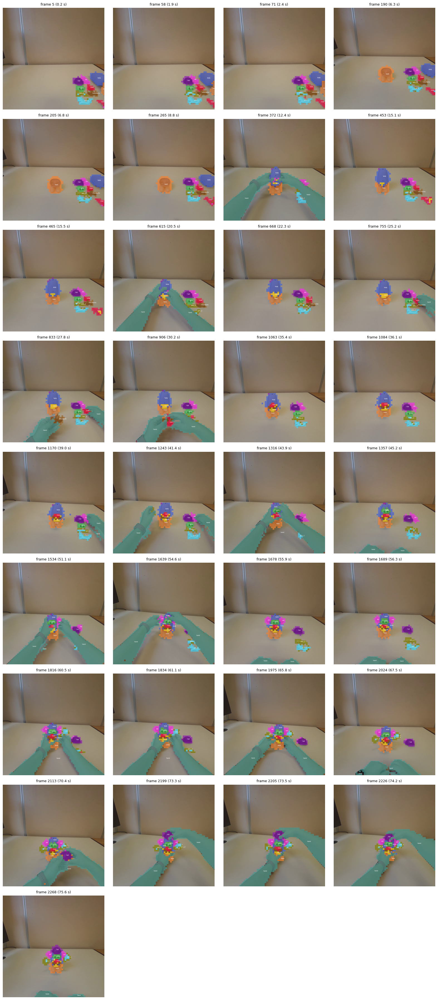

In [32]:
# 11.3 Snapshots of each moment C-RADIO was run (the full video is in the outputs folder)
n_cols = 4
n_rows = int(np.ceil(len(snapshots) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows), squeeze=False)
for ax in axes.flat:
    ax.axis("off")
for ax, (index, image) in zip(axes.flat, snapshots):
    ax.imshow(image)
    ax.set_title(f"frame {index} ({index / fps:.1f} s)", fontsize=9)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / f"{DEMO_VIDEO.stem}_snapshots.png", dpi=120, bbox_inches="tight")
plt.show()

Observation 11.3:
The snapshots follow the whole assembly of assembly_2: all pieces loose (0.2–2.4 s), base alone (6.3 s), body on base (12.4 s), mouth (22.3 s), nose and moustache joined in hand (27.8–30.2 s) and then mounted on the face (35.4 s), eyes (45.2 s), ears (51.1 s), arms (60.5 s), hat (75.6 s). Each piece appears mounted at the right moment. Hands are recognized when present, and pieces held in hand keep their class (nose and moustache, 27.8–30.2 s). Errors are those seen in Section 10: arms mixed between arm_1 and arm_2, both loose and mounted; the empty mouth slot predicted as mouth before the mouth is mounted (15.1–15.5 s); a mouth lying on its side predicted mostly as nose.

References Section 11: no new reference. Motion gating uses a simple frame difference; its parameters are provisional, as this gating will be replaced by continuous perception.

## Section 12 - End-to-end latency

Time of each pipeline step on one validation frame (mean of 50 runs after GPU warm-up). At 30 fps the budget per frame is about 33 ms. Overlay rendering is measured separately: it is visualization, not perception.

In [33]:
# 12.1 Latency of each pipeline step on one validation frame (GPU warm-up excluded)
N_WARMUP, N_RUNS = 5, 50
latency_image = Image.open(VALIDATION_FRAMES[0]["image_path"]).convert("RGB")
latency_rgb = np.asarray(latency_image)
latency_gray = cv2.resize(cv2.cvtColor(latency_rgb, cv2.COLOR_RGB2GRAY), MOTION_SIZE)


def timed(fn):
    """Run fn and return (result, elapsed milliseconds), waiting for the GPU before and after."""
    torch.cuda.synchronize()
    start = time.perf_counter()
    result = fn()
    torch.cuda.synchronize()
    return result, (time.perf_counter() - start) * 1000


def model_forward(pixel_values):
    with torch.no_grad(), torch.autocast(DEVICE, dtype=DTYPE):
        return model(pixel_values)


# Model input computed once, to time the forward pass alone
pixel_values, _ = extractor.preprocess(latency_image)

# Warm-up: the first GPU runs are slower (memory allocation, kernel selection) and are not measured
for _ in range(N_WARMUP):
    features, _ = extractor.extract(latency_image)
    labels, _ = classify_patches(features, prototype_matrix, CONFIDENCE_MARGIN)

steps = {
    "motion score (every frame)":           lambda: motion_score(latency_gray, latency_gray),
    "C-RADIO forward only":                 lambda: model_forward(pixel_values),
    "feature extraction (preproc + model)": lambda: extractor.extract(latency_image),
    "classification":                       lambda: classify_patches(features, prototype_matrix, CONFIDENCE_MARGIN),
    "overlay rendering (visualization)":    lambda: render_overlay(latency_rgb, labels, MIN_BLOB_PATCHES),
}
timings = {name: [timed(fn)[1] for _ in range(N_RUNS)] for name, fn in steps.items()}

latency_table = pd.DataFrame({
    name: {"mean (ms)": np.mean(t), "std (ms)": np.std(t)} for name, t in timings.items()
}).T
perception_ms = latency_table.loc["feature extraction (preproc + model)", "mean (ms)"] + \
                latency_table.loc["classification", "mean (ms)"]
display(latency_table.round(2))
print(f"Perception (extraction + classification): {perception_ms:.1f} ms  ->  {1000 / perception_ms:.1f} fps")
print(f"GPU: {torch.cuda.get_device_name(0)}")

,mean (ms),std (ms)
motion score (every frame),0.29,0.10
C-RADIO forward only,358.34,3.71
feature extraction (preproc + model),377.82,2.12
classification,27.42,3.24
overlay rendering (visualization),50.41,6.00


Perception (extraction + classification): 405.2 ms  ->  2.5 fps
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


Observation 12.1:
C-RADIO takes 358 ms of the 405 ms needed for perception (88%). Classification adds 27 ms, the motion score 0.3 ms. Perception runs at 2.5 fps on this GPU at 1024x1024, far from the 30 fps of the video. With motion gating this is acceptable: the cost per frame is only the motion score, and pieces appear about 0.5 s after the scene becomes still (5 stable frames + perception). Continuous perception is not possible in this configuration. The options to study are lower resolution, a stronger GPU (e.g. a server receiving frames from the headset), model optimization, or a lower target rate.

References Section 12: no new reference. Timings are specific to the GPU reported above.

## Limitations and next steps
Dataset: one operator and one environment (split by recording, not by operator). In 1_disassembled_controlled_caos pants and shoes are separated, outside the base definition. Hand comes from a single reference frame. assembly_1 (test) and assembly_2 (validation) were inspected once in v1-baseline, before any change to the method. From v1.1 on, this notebook reads only validation frames.

Recognition: arm_1 and arm_2 are confused (similar prototypes, arm_2 with 11 patches); a mouth lying on its side is predicted as nose or ear; loose eyes are predicted as arm_2 in 1_disassembled_controlled_caos; the empty mouth slot on the body is predicted as mouth.

Provisional choices: the background margin (0.03) → margin study; the empty mouth slot predicted as mouth is not separated by a top1–top2 gap on validation (10.3) → support-set study (a reference frame showing the empty slot as body); which and how many reference frames → support-set study; motion gating → continuous perception.

Latency: 405 ms per frame at 1024x1024 on an RTX 4060 Laptop (2.5 fps): continuous perception needs lower resolution, a stronger GPU, model optimization or a lower target rate.

Evaluation: qualitative only. Quantitative evaluation (per-class IoU) on annotated validation frames is done in the support-set study.

## Appendix A - Sensitivity checks

Checks of the design choices of Section 6: they verify that the results do not depend on them (A.1, A.3) and explain the patch-norm outliers (A.2).

A.1 Raw vs normalized mean. Prototypes rebuilt without L2-normalizing the patches first.

In [34]:
# A.1 Raw vs normalized mean
raw_vs_normalized = {}
for name in prototype_names:
    raw_chunks = [ref["features"][ref["patch_labels"] == CLASS_NAMES.index(name)] for ref in REFERENCE_FRAMES]
    raw_pooled = np.concatenate([c for c in raw_chunks if len(c)])
    raw_prototype = l2_normalize(raw_pooled.mean(axis=0))          # alternative: mean of raw vectors
    norms = np.linalg.norm(raw_pooled, axis=1)
    raw_vs_normalized[name] = {
        "cosine(raw, normalized)": float(raw_prototype @ prototypes[name]),
        "patch norm CV": float(norms.std() / norms.mean()),       # how much patch lengths vary
    }
bg_norms_all = np.concatenate([np.linalg.norm(r["features"][r["patch_labels"] == 0], axis=-1) for r in REFERENCE_FRAMES])
bg_clean = bg_norms_all[bg_norms_all <= EXTREME_NORM_FACTOR * np.median(bg_norms_all)]
print(f"Background norm CV: {bg_norms_all.std() / bg_norms_all.mean():.3f} (all), "
      f"{bg_clean.std() / bg_clean.mean():.3f} (without extreme patches)")

display(pd.DataFrame(raw_vs_normalized).T.round(4))

Background norm CV: 0.580 (all), 0.046 (without extreme patches)


,"cosine(raw, normalized)",patch norm CV
background,0.9999,0.5799
body,1.0000,0.0510
base,1.0000,0.0562
hat,1.0000,0.0410
eyes,1.0000,0.0408
ear,0.9999,0.0460
nose,0.9999,0.0485
moustache,0.9998,0.0727
mouth,0.9998,0.0654
arm_1,1.0000,0.0486


Observation A.1: Raw and normalized means give practically the same prototypes (cosine ≥ 0.9998): piece patch norms vary only 4–7%. Normalization is kept because it is consistent with cosine similarity, and it is verified not to change the result. Background norms seem to vary much more (CV 0.580), but without the 21 fixed-pattern artifact patches (see A.2) the CV drops to 0.046, in line with the pieces. Normalization makes these patches weigh like any other patch.

A.2 Patch norms. Distribution of patch-feature norms and test for fixed-pattern artifacts.

Median norm   background: 36.3   pieces: 38.3
Outlier threshold: 41.9
Background outliers: 111 / 26744 (0.42%)
  of which on the image border: 68%
  max outlier norm / median background norm: 29.0x
Register-related config entries: none found in config
Share of all patches on the border (expected if random): 12%
Extreme outliers (> EXTREME_NORM_FACTORx median): 21, of which on the border: 100%
5_assembled_f0002                [(0, 55), (0, 56), (0, 57)]
caos_f0149                       [(0, 55), (0, 56), (0, 57)]
3_disassembled_ordered_f0001     [(0, 55), (0, 56), (0, 57)]
2_disassembled_caos_f0016        [(0, 55), (0, 56), (0, 57)]
Take_3_1_Base_f0099              [(0, 55), (0, 56), (0, 57)]
Take_3_1_Base_f0131              [(0, 55), (0, 56), (0, 57)]
caos_f0211                       [(0, 55), (0, 56), (0, 57)]


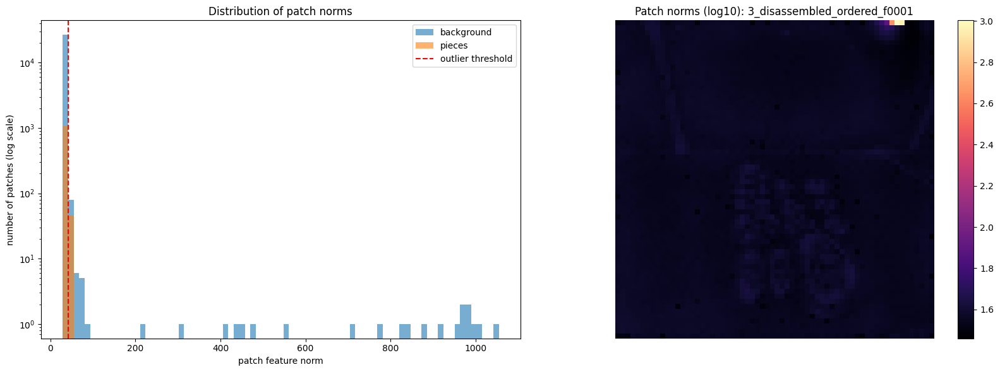

In [35]:
# A.2 Patch norms and fixed-pattern artifacts
all_norms, all_ids, on_border = [], [], []
for ref in REFERENCE_FRAMES:
    norms = np.linalg.norm(ref["features"], axis=-1)                 # (h, w): length of each patch vector
    border = np.zeros_like(norms, dtype=bool)
    b = PCA_BORDER_EXCLUDE
    border[:b, :] = border[-b:, :] = border[:, :b] = border[:, -b:] = True
    all_norms.append(norms.ravel())
    all_ids.append(ref["patch_labels"].ravel())
    on_border.append(border.ravel())
all_norms, all_ids, on_border = map(np.concatenate, (all_norms, all_ids, on_border))

bg_norms = all_norms[all_ids == 0]
piece_norms = all_norms[(all_ids > 0) & (all_ids < IGNORE_ID)]

# Outliers: Tukey's far-out fence (Q3 + 3*IQR), a standard, parameter-free definition
q1, q3 = np.percentile(bg_norms, [25, 75])
outlier_threshold = q3 + 3 * (q3 - q1)
is_bg_outlier = (all_ids == 0) & (all_norms > outlier_threshold)

print(f"Median norm   background: {np.median(bg_norms):.1f}   pieces: {np.median(piece_norms):.1f}")
print(f"Outlier threshold: {outlier_threshold:.1f}")
print(f"Background outliers: {is_bg_outlier.sum()} / {len(bg_norms)} ({is_bg_outlier.sum() / len(bg_norms):.2%})")
if is_bg_outlier.any():
    print(f"  of which on the image border: {on_border[is_bg_outlier].mean():.0%}")
    print(f"  max outlier norm / median background norm: {all_norms[is_bg_outlier].max() / np.median(bg_norms):.1f}x")

# Does this C-RADIO version use register tokens? (registers are the fix proposed by Darcet et al.)
print("Register-related config entries:",
      {k: v for k, v in model.config.to_dict().items() if "reg" in k.lower()} or "none found in config")

# Plots: histogram + norm map of the example frame (same frame as the PCA in 3.6)
example_ref = next(r for r in REFERENCE_FRAMES if r["frame"] == EXAMPLE_FRAME.stem)
example_norms = np.linalg.norm(example_ref["features"], axis=-1)

extreme = (all_ids == 0) & (all_norms > EXTREME_NORM_FACTOR * np.median(bg_norms))
print(f"Share of all patches on the border (expected if random): {on_border.mean():.0%}")
print(f"Extreme outliers (> EXTREME_NORM_FACTORx median): {extreme.sum()}, of which on the border: {on_border[extreme].mean():.0%}")
# Are extreme patches always at the same grid positions? (position-dependent fixed-pattern noise)
extreme_threshold = EXTREME_NORM_FACTOR * np.median(bg_norms)
for ref in REFERENCE_FRAMES:
    rows, cols = np.where(np.linalg.norm(ref["features"], axis=-1) > extreme_threshold)
    print(f"{ref['frame']:<32} {list(zip(rows.tolist(), cols.tolist()))}")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
bins = np.linspace(all_norms.min(), all_norms.max(), 80)
axes[0].hist(bg_norms, bins=bins, alpha=0.6, label="background", log=True)
axes[0].hist(piece_norms, bins=bins, alpha=0.6, label="pieces", log=True)
axes[0].axvline(outlier_threshold, color="red", linestyle="--", label="outlier threshold")
axes[0].set_xlabel("patch feature norm")
axes[0].set_ylabel("number of patches (log scale)")
axes[0].legend()
axes[0].set_title("Distribution of patch norms")

im = axes[1].imshow(np.log10(example_norms), cmap="magma")
axes[1].set_title(f"Patch norms (log10): {example_ref['frame']}")
axes[1].axis("off")
fig.colorbar(im, ax=axes[1], fraction=0.046)
plt.tight_layout()
plt.show()

Extreme patches in a uniform grey image: [[0, 56], [0, 57], [0, 58]]


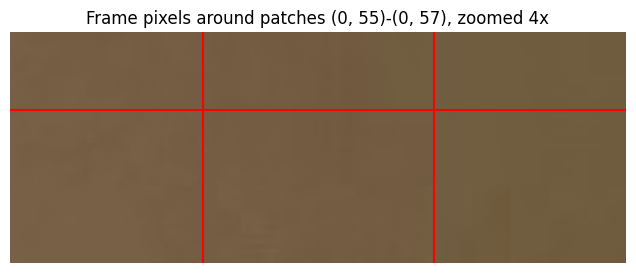

In [36]:
# A.2 (continued) Fixed-pattern test: uniform grey image
# Is the anomaly produced by the model (fixed-pattern noise) or by something in the frames?
# 1. Feed a uniform grey image: it has no content, so any anomaly comes from the model itself.
blank = Image.new("RGB", (1024, 1024), (128, 128, 128))
blank_features, _ = extractor.extract(blank)
blank_norms = np.linalg.norm(blank_features, axis=-1)
print("Extreme patches in a uniform grey image:",
      np.argwhere(blank_norms > EXTREME_NORM_FACTOR * np.median(blank_norms)).tolist())

# 2. Look at the pixels of that region in a real frame (patches (0, 55)-(0, 57) = x 880-928, y 0-16).
region = example_image.crop((840, 0, 968, 48)).resize((512, 192), Image.Resampling.NEAREST)
plt.figure(figsize=(8, 3))
plt.imshow(region)
plt.axvline((880 - 840) * 4, color="red")
plt.axvline((928 - 840) * 4, color="red")
plt.axhline(16 * 4, color="red")
plt.title("Frame pixels around patches (0, 55)-(0, 57), zoomed 4x")
plt.axis("off")
plt.show()

Observation A.2: Typical patch norms are similar for background and pieces (median 36.3 vs 38.3). 111 background patches (0.42%) exceed Tukey's far-out fence. 21 of them are extreme (up to 29x the median norm): they are always the same three patches, row 0, columns 55–57, in all 7 reference frames. The frame pixels there are plain wall, and a uniform grey image produces the same anomaly at row 0, columns 56–58: the artifact comes from the model, not from the images. This is the position-dependent fixed-pattern noise inherited from the teachers and described in the C-RADIOv4 tech report (Sec. 2.3, Fig. 2; DVT, Yang et al. 2024), which the training mitigates but does not fully remove at the border of the backbone features. The extreme patches entered the background prototype, but after normalization they weigh like any other patch (A.1). Section 10.2 shows they are always classified as background, so no filtering is needed.

A.3 Labelling rule check. Prototypes are rebuilt with the center-pixel rule (5.3), using the same features and pixel maps: only the patch labelling rule changes. If the two versions are much closer to each other than two different classes are, the rule does not affect the prototypes.

In [37]:
# A.3 Does the labelling rule change the prototypes? Center-pixel rule vs coverage rule
center = PATCH_SIZE // 2

# Same features, same pixel maps: only the patch labelling rule changes.
# Alternative rule: each patch takes the label of its center pixel (IGNORE_ID and background included).
center_rule_frames = [
    {"features": ref["features"],
     "patch_labels": ref["pixel_map"][center::PATCH_SIZE, center::PATCH_SIZE]}
    for ref in REFERENCE_FRAMES
]
center_prototypes, center_patch_counts = build_prototypes(center_rule_frames)

rule_comparison = pd.DataFrame({
    name: {
        "patches (center pixel)": center_patch_counts[name],
        "patches (coverage >= 0.5)": prototype_patch_counts[name],
        "cosine(center, coverage)": float(center_prototypes[name] @ prototypes[name]),
    }
    for name in prototype_names
}).T
rule_comparison["patches (center pixel)"] = rule_comparison["patches (center pixel)"].astype(int)
rule_comparison["patches (coverage >= 0.5)"] = rule_comparison["patches (coverage >= 0.5)"].astype(int)
display(rule_comparison.round(4))

,patches (center pixel),patches (coverage >= 0.5),"cosine(center, coverage)"
background,27209,26744,0.9999
body,234,226,0.9999
base,186,184,0.9999
hat,37,38,0.9992
eyes,25,24,0.9995
ear,40,39,0.9999
nose,26,23,0.9991
moustache,28,27,0.9996
mouth,21,20,0.9996
arm_1,33,28,0.9987


In [38]:
# A.3 (continued) Labelling-rule shift vs distance to the nearest class (8.2)
nearest_table["rule shift"] = [1 - rule_comparison.loc[name, "cosine(center, coverage)"] for name in nearest_table.index]
nearest_table["distance / rule shift"] = nearest_table["distance (1 - cosine)"] / nearest_table["rule shift"].clip(lower=1e-6)
display(nearest_table.round(4))

,nearest class,cosine,distance (1 - cosine),rule shift,distance / rule shift
class,,,,,
arm_1,arm_2,0.9504,0.0496,0.0013,38.8025
arm_2,arm_1,0.9504,0.0496,0.0018,27.0870
nose,ear,0.8932,0.1068,0.0009,119.9967
ear,nose,0.8932,0.1068,0.0001,1039.9251
moustache,nose,0.8644,0.1356,0.0004,337.3894
mouth,ear,0.8534,0.1466,0.0004,395.6727
base,hat,0.8504,0.1496,0.0001,2017.2476
hat,base,0.8504,0.1496,0.0008,177.1089
body,base,0.8286,0.1714,0.0001,2402.9574


Observation A.3: The labelling rule does not affect the prototypes: cosine between center-pixel and coverage prototypes is ≥ 0.998 for all classes. The largest changes are for thin pieces (arm_2 0.9982, arm_1 0.9987, nose 0.9991). These changes are at least 27 times smaller than the distance between each class and its nearest class (8.2). The coverage rule is kept because it is cleaner and justified (5.3).

References Appendix A: C-RADIOv4 tech report (Sec. 2.3, Fig. 2) and DVT (Yang et al. 2024) for position-dependent fixed-pattern noise; Darcet et al. 2024 for high-norm artifact tokens in ViTs.